# Instituto / Universidad: **CENTRO UNIVERSITARIO UAEM ZUMPANGO**

## Programa Educativo: Ingeniería en Computación

### Asignatura: Investigación de Operaciones

---

# Práctica 4. Programación Lineal

**Actividad integradora:** Implementación de Modelos de Investigación de Operaciones mediante Python y Jupyter Notebook

**Periodo:** 2026-B

**Integrantes del equipo:**

| No. | Nombre completo |
|:---:|:----------------|
| 1 | Fernando Dante Rodriguez Silva |  
| 2 | Jonathan Alberto López Fabián |
| 3 | Brayan Michel Aguilar Torres |  

**Fecha de elaboración:** 16 de noviembre de 2026

**Herramientas:** Python 3, Jupyter Notebook, NetworkX, Matplotlib, NumPy, Pandas y SciPy.


---
# 1. Título del problema

**Asignación óptima de los recursos de un clúster en la nube (vCPU, memoria RAM y almacenamiento) para maximizar la ganancia mensual**

---

# 2. Descripción y planteamiento

Una empresa de *hosting* administra un clúster con una capacidad fija de **320 vCPU**, **1,120 GB de memoria RAM** y **9,500 GB de almacenamiento**. Puede rentar dos tipos de máquinas virtuales (VM):

| Tipo de VM | vCPU | RAM (GB) | Almacenamiento (GB) | Ganancia mensual (USD) |
|:-----------|:----:|:--------:|:-------------------:|:----------------------:|
| **Cómputo optimizado** ($x_1$) | 4 | 8 | 100 | 40 |
| **Memoria optimizada** ($x_2$) | 2 | 16 | 100 | 30 |

*(Los valores de ganancia y consumo son supuestos ilustrativos del problema.)*

**Pregunta:** ¿cuántas VM de cada tipo conviene mantener activas para obtener la **máxima ganancia mensual** sin exceder la capacidad del clúster?

**Relación con las Tecnologías de la Información:** es un problema típico de **planeación de capacidad** y de *cloud computing* (dimensionamiento de clústeres, asignación de recursos en centros de datos, mezcla de instancias). Además de la solución óptima, el modelo permite saber **qué recurso es el cuello de botella** y **cuánto vale ampliar cada recurso** (precios sombra).

---

# 3. Formulación matemática

**Variables de decisión:**

- $x_1$ = número de VM de cómputo optimizado activas.
- $x_2$ = número de VM de memoria optimizada activas.

**Función objetivo** (maximizar la ganancia mensual en USD):

$$\max Z = 40x_1 + 30x_2$$

**Restricciones:**

$$\begin{aligned}
4x_1 + 2x_2 &\le 320 && \text{(vCPU disponibles)}\\
8x_1 + 16x_2 &\le 1120 && \text{(RAM disponible, GB)}\\
100x_1 + 100x_2 &\le 9500 && \text{(almacenamiento disponible, GB)}\\
x_1,\ x_2 &\ge 0 && \text{(no negatividad)}
\end{aligned}$$

Como el modelo tiene **dos variables**, se resolverá primero con el **método gráfico** (graficando restricción por restricción), después se confirmará con **Python (SciPy)** y finalmente se interpretará la solución, las holguras y los precios sombra.

---
# 4. Importación de bibliotecas

Se usa **NumPy** (álgebra de las intersecciones), **Pandas** (tablas), **Matplotlib** (gráficas) y **SciPy** (`linprog`, solucionador de programación lineal con el método HiGHS).

In [1]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy.optimize import linprog

print("NumPy  :", np.__version__)
print("Pandas :", pd.__version__)
print("SciPy  :", scipy.__version__)
print("Bibliotecas importadas correctamente.")

NumPy  : 2.5.4
Pandas : 3.0.6
SciPy  : 1.18.1
Bibliotecas importadas correctamente.


---
# 5. Definición de datos

Se definen los coeficientes del modelo en forma matricial: vector de costos (ganancias) $c$, matriz tecnológica $A$ y vector de recursos disponibles $b$, de manera que el modelo es

$$\max\; c^{T}x \quad \text{s.a.}\quad Ax\le b,\; x\ge 0$$

Los datos se guardan en el archivo complementario `p4_datos_modelo.csv`.

In [2]:
nombres_vars = ["x1 (cómputo optimizado)", "x2 (memoria optimizada)"]
c = np.array([40, 30])                      # ganancia mensual por VM (USD)

nombres_rest = ["vCPU", "RAM (GB)", "Almacenamiento (GB)"]
A = np.array([[4, 2],                       # vCPU por VM
              [8, 16],                      # GB de RAM por VM
              [100, 100]])                  # GB de disco por VM
b = np.array([320, 1120, 9500])             # capacidad del clúster

df_datos = pd.DataFrame(A, index=nombres_rest, columns=["x1", "x2"])
df_datos["disponible (b)"] = b
df_datos.loc["Ganancia (c)"] = [c[0], c[1], ""]
df_datos.to_csv("p4_datos_modelo.csv")
print(df_datos.to_string())

print("\nModelo:  max Z =", f"{c[0]}x1 + {c[1]}x2")
for i, nom in enumerate(nombres_rest):
    print(f"   {A[i,0]:>3}x1 + {A[i,1]:>3}x2 <= {b[i]:>5}    ({nom})")
print("   x1, x2 >= 0")

                      x1   x2 disponible (b)
vCPU                   4    2            320
RAM (GB)               8   16           1120
Almacenamiento (GB)  100  100           9500
Ganancia (c)          40   30               

Modelo:  max Z = 40x1 + 30x2
     4x1 +   2x2 <=   320    (vCPU)
     8x1 +  16x2 <=  1120    (RAM (GB))
   100x1 + 100x2 <=  9500    (Almacenamiento (GB))
   x1, x2 >= 0


---
## 5.1 Funciones auxiliares de graficación

`dibujar_restricciones(k)` grafica las **primeras $k$ restricciones**: cada recta $a_1x_1+a_2x_2=b$ y la **región que cumple todas las restricciones acumuladas** (sombreada), junto con $x_1,x_2\ge 0$. Así se ve cómo se va **reduciendo la región factible** con cada restricción.

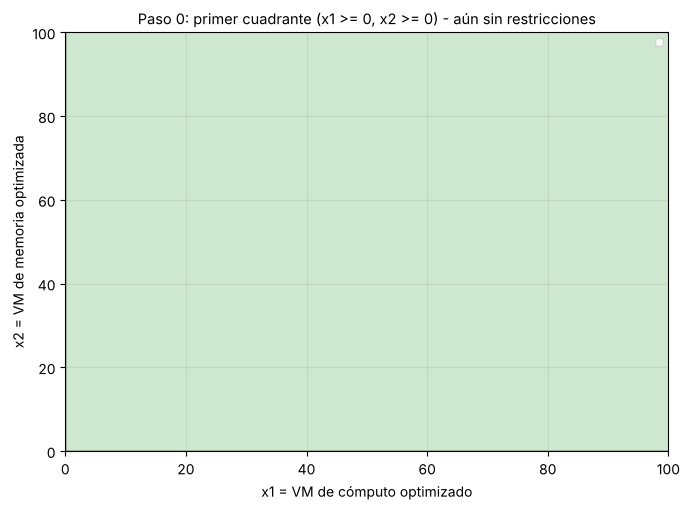

In [3]:
colores = ["#e53935", "#1e88e5", "#43a047"]
xs = np.linspace(0, 100, 600)
X1, X2 = np.meshgrid(xs, xs)

def region(k):
    m = (X1 >= 0) & (X2 >= 0)
    for i in range(k):
        m &= (A[i, 0] * X1 + A[i, 1] * X2 <= b[i])
    return m

def recta(i):
    return (b[i] - A[i, 0] * xs) / A[i, 1]

def dibujar_restricciones(k, titulo, ax=None, vertices=None):
    propio = ax is None
    if propio:
        fig, ax = plt.subplots(figsize=(7, 5.2))
    ax.contourf(X1, X2, region(k).astype(int), levels=[0.5, 1.5], colors=["#a5d6a7"], alpha=0.55)
    for i in range(k):
        y = recta(i)
        ax.plot(xs, y, color=colores[i], lw=2.4, label=f"R{i+1}: {A[i,0]}x1 + {A[i,1]}x2 <= {b[i]}  ({nombres_rest[i]})")
    ax.axhline(0, color="black", lw=1)
    ax.axvline(0, color="black", lw=1)
    ax.set_xlim(0, 100); ax.set_ylim(0, 100)
    ax.set_xlabel("x1 = VM de cómputo optimizado")
    ax.set_ylabel("x2 = VM de memoria optimizada")
    ax.set_title(titulo, fontsize=10.5)
    ax.grid(alpha=0.3)
    ax.legend(loc="upper right", fontsize=7.5)
    if propio:
        plt.tight_layout()
        plt.show()

# Paso 0: plano de decision con x1, x2 >= 0 (primer cuadrante)
dibujar_restricciones(0, "Paso 0: primer cuadrante (x1 >= 0, x2 >= 0) - aún sin restricciones")

---
# 6. Desarrollo del algoritmo (método gráfico)

Para cada restricción se obtienen los **puntos de corte con los ejes** (haciendo una variable igual a cero) y se traza la recta; después se elige el semiplano que cumple la desigualdad ($\le$, es decir, el lado que contiene al origen) y se intersecta con la región acumulada.

---
# 7. Ejecución paso a paso

## 7.1 Restricción 1: vCPU

$4x_1+2x_2\le 320$. Cortes con los ejes: si $x_2=0\Rightarrow x_1=80$; si $x_1=0\Rightarrow x_2=160$ (fuera de la ventana, la recta sale por arriba).

R1 (vCPU): 4x1 + 2x2 <= 320
   Corte con el eje x1 (x2 = 0): 80.0
   Corte con el eje x2 (x1 = 0): 160.0
   ¿El origen (0,0) cumple la restricción? -> True => se sombrea el lado del origen


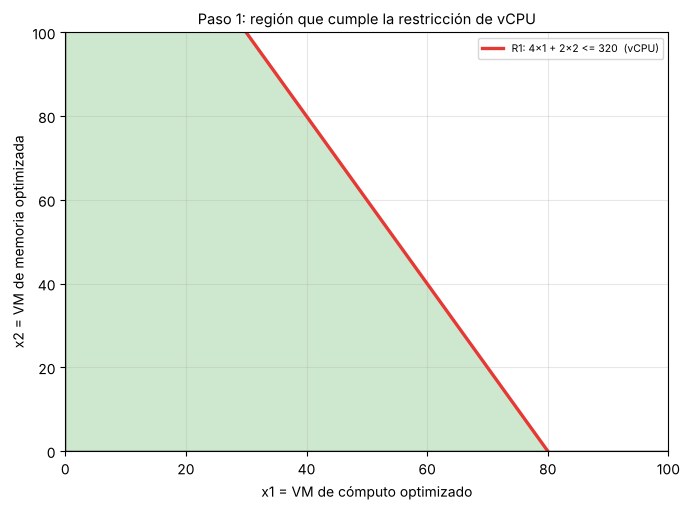

In [4]:
i = 0
print(f"R1 ({nombres_rest[i]}): {A[i,0]}x1 + {A[i,1]}x2 <= {b[i]}")
print("   Corte con el eje x1 (x2 = 0):", b[i] / A[i, 0])
print("   Corte con el eje x2 (x1 = 0):", b[i] / A[i, 1])
print("   ¿El origen (0,0) cumple la restricción? ->", 0 <= b[i], "=> se sombrea el lado del origen")
dibujar_restricciones(1, "Paso 1: región que cumple la restricción de vCPU")

---
## 7.2 Restricción 2: memoria RAM

$8x_1+16x_2\le 1120$. Cortes: $x_2=0\Rightarrow x_1=140$; $x_1=0\Rightarrow x_2=70$.

R2 (RAM (GB)): 8x1 + 16x2 <= 1120
   Corte con el eje x1 (x2 = 0): 140.0
   Corte con el eje x2 (x1 = 0): 70.0
   ¿El origen (0,0) cumple la restricción? -> True => se sombrea el lado del origen


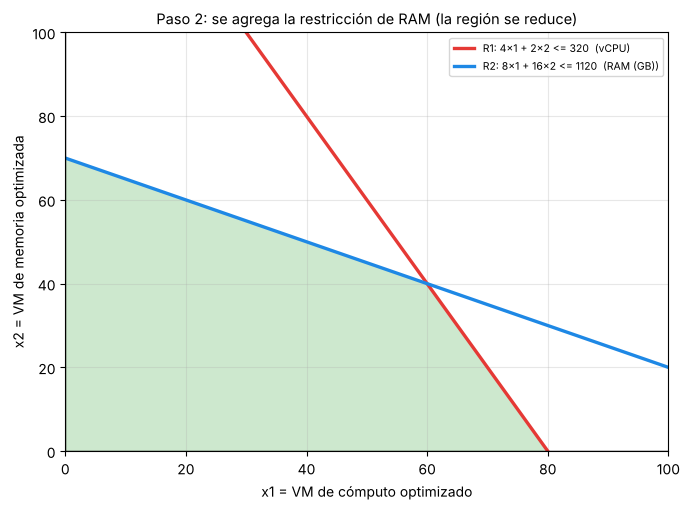

In [5]:
i = 1
print(f"R2 ({nombres_rest[i]}): {A[i,0]}x1 + {A[i,1]}x2 <= {b[i]}")
print("   Corte con el eje x1 (x2 = 0):", b[i] / A[i, 0])
print("   Corte con el eje x2 (x1 = 0):", b[i] / A[i, 1])
print("   ¿El origen (0,0) cumple la restricción? ->", 0 <= b[i], "=> se sombrea el lado del origen")
dibujar_restricciones(2, "Paso 2: se agrega la restricción de RAM (la región se reduce)")

---
## 7.3 Restricción 3: almacenamiento

$100x_1+100x_2\le 9500$, equivalente a $x_1+x_2\le 95$. Cortes: $x_2=0\Rightarrow x_1=95$; $x_1=0\Rightarrow x_2=95$.

R3 (Almacenamiento (GB)): 100x1 + 100x2 <= 9500
   Corte con el eje x1 (x2 = 0): 95.0
   Corte con el eje x2 (x1 = 0): 95.0
   ¿El origen (0,0) cumple la restricción? -> True => se sombrea el lado del origen


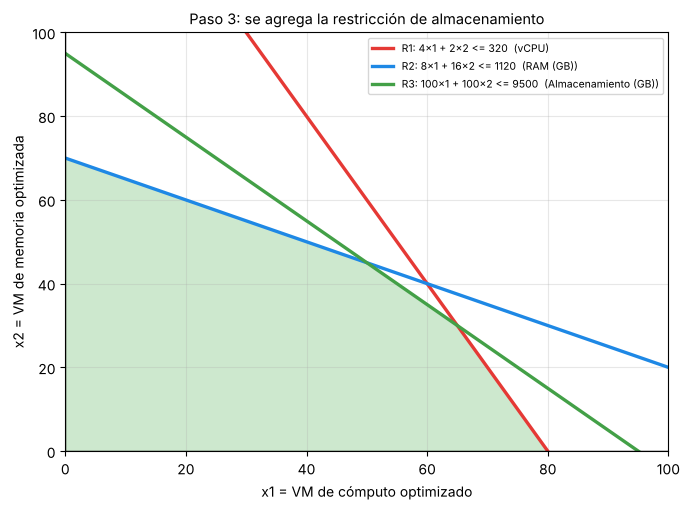

In [6]:
i = 2
print(f"R3 ({nombres_rest[i]}): {A[i,0]}x1 + {A[i,1]}x2 <= {b[i]}")
print("   Corte con el eje x1 (x2 = 0):", b[i] / A[i, 0])
print("   Corte con el eje x2 (x1 = 0):", b[i] / A[i, 1])
print("   ¿El origen (0,0) cumple la restricción? ->", 0 <= b[i], "=> se sombrea el lado del origen")
dibujar_restricciones(3, "Paso 3: se agrega la restricción de almacenamiento")

---
## 7.4 Región factible final

La región factible es la **intersección** de las tres restricciones con $x_1,x_2\ge 0$: es un polígono convexo. Como el problema es lineal, si existe un óptimo, éste se encuentra en un **vértice** (punto esquina) de la región.

Para encontrar los vértices se calcula la **intersección de cada par de rectas frontera** (las 3 restricciones y los 2 ejes: $\binom{5}{2}=10$ pares) resolviendo el sistema $2\times 2$ y se conservan sólo los puntos que **cumplen todas las restricciones** (puntos factibles).

              Intersección de Punto (x1, x2) ¿Factible? Z = 40x1 + 30x2
             R1 vCPU y R2 RAM (60.00, 40.00)         no               -
           R1 vCPU y R3 Disco (65.00, 30.00)         SÍ         3500.00
      R1 vCPU y Eje x2 (x1=0) (0.00, 160.00)         no               -
      R1 vCPU y Eje x1 (x2=0)  (80.00, 0.00)         SÍ         3200.00
            R2 RAM y R3 Disco (50.00, 45.00)         SÍ         3350.00
       R2 RAM y Eje x2 (x1=0)  (0.00, 70.00)         SÍ         2100.00
       R2 RAM y Eje x1 (x2=0) (140.00, 0.00)         no               -
     R3 Disco y Eje x2 (x1=0)  (0.00, 95.00)         no               -
     R3 Disco y Eje x1 (x2=0)  (95.00, 0.00)         no               -
Eje x2 (x1=0) y Eje x1 (x2=0)   (0.00, 0.00)         SÍ            0.00

Vértices de la región factible: [(0.0, 0.0), (0.0, 70.0), (50.0, 45.0), (65.0, 30.0), (80.0, 0.0)]


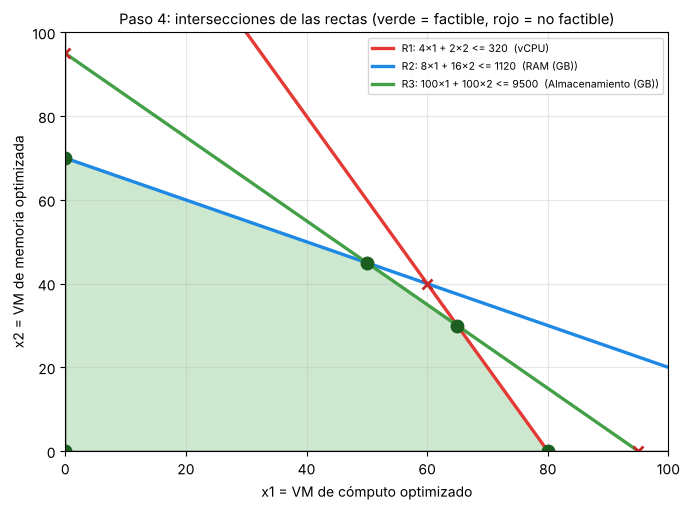

In [7]:
# Rectas frontera: (a1, a2, b)
fronteras = [("R1 vCPU", A[0, 0], A[0, 1], b[0]),
             ("R2 RAM", A[1, 0], A[1, 1], b[1]),
             ("R3 Disco", A[2, 0], A[2, 1], b[2]),
             ("Eje x2 (x1=0)", 1, 0, 0),
             ("Eje x1 (x2=0)", 0, 1, 0)]

def es_factible(p, tol=1e-9):
    return p[0] >= -tol and p[1] >= -tol and np.all(A @ p <= b + tol)

filas, vertices = [], []
for (n1, a1, a2, r1), (n2, a3, a4, r2) in itertools.combinations(fronteras, 2):
    M = np.array([[a1, a2], [a3, a4]], dtype=float)
    if abs(np.linalg.det(M)) < 1e-12:
        filas.append([f"{n1} y {n2}", "paralelas", "-", "-"])
        continue
    p = np.linalg.solve(M, np.array([r1, r2], dtype=float))
    fact = es_factible(p)
    filas.append([f"{n1} y {n2}", f"({p[0]:.2f}, {p[1]:.2f})", "SÍ" if fact else "no", f"{c @ p:.2f}" if fact else "-"])
    if fact:
        vertices.append(tuple(float(x) for x in np.round(p, 6)))

print(pd.DataFrame(filas, columns=["Intersección de", "Punto (x1, x2)", "¿Factible?", "Z = 40x1 + 30x2"]).to_string(index=False))
vertices = sorted(set(vertices))
print("\nVértices de la región factible:", vertices)

# Grafica de los 10 puntos
fig, ax = plt.subplots(figsize=(7, 5.2))
dibujar_restricciones(3, "Paso 4: intersecciones de las rectas (verde = factible, rojo = no factible)", ax=ax)
for (n1, a1, a2, r1), (n2, a3, a4, r2) in itertools.combinations(fronteras, 2):
    M = np.array([[a1, a2], [a3, a4]], dtype=float)
    if abs(np.linalg.det(M)) < 1e-12:
        continue
    p = np.linalg.solve(M, np.array([r1, r2], dtype=float))
    if -1 <= p[0] <= 100 and -1 <= p[1] <= 100:
        ax.plot(*p, "o" if es_factible(p) else "x", color="#1b5e20" if es_factible(p) else "#c62828",
                ms=8 if es_factible(p) else 7, mew=2)
plt.tight_layout()
plt.show()

---
## 7.5 Evaluación de la función objetivo en cada vértice

Se evalúa $Z=40x_1+30x_2$ en los **5 vértices factibles**. El mayor valor corresponde a la **solución óptima**.

vértice   x1   x2      Z
     V1  0.0  0.0    0.0
     V2  0.0 70.0 2100.0
     V3 50.0 45.0 3350.0
     V4 65.0 30.0 3500.0
     V5 80.0  0.0 3200.0

Máximo: V4 = (65, 30)  con Z = 3500 USD


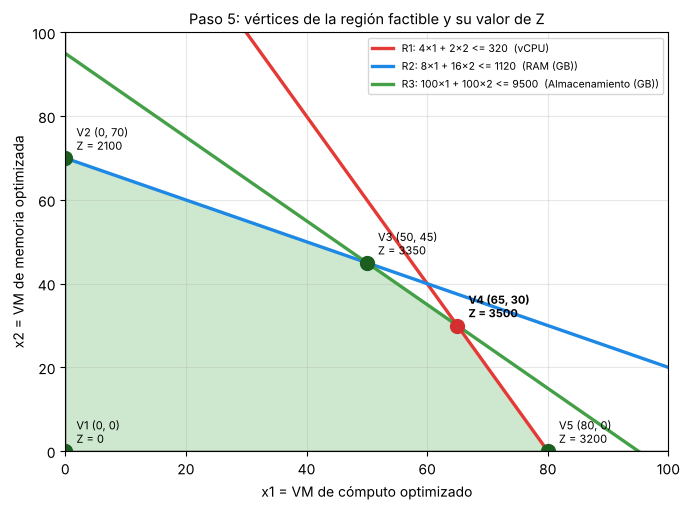

In [8]:
df_v = pd.DataFrame([(f"V{i+1}", v[0], v[1], c @ np.array(v)) for i, v in enumerate(vertices)],
                    columns=["vértice", "x1", "x2", "Z"])
print(df_v.to_string(index=False))
mejor = df_v.loc[df_v["Z"].idxmax()]
print(f"\nMáximo: {mejor['vértice']} = ({mejor['x1']:.0f}, {mejor['x2']:.0f})  con Z = {mejor['Z']:.0f} USD")

fig, ax = plt.subplots(figsize=(7, 5.2))
dibujar_restricciones(3, "Paso 5: vértices de la región factible y su valor de Z", ax=ax)
for _, r in df_v.iterrows():
    es_mejor = r["Z"] == mejor["Z"]
    ax.plot(r["x1"], r["x2"], "o", color="#d32f2f" if es_mejor else "#1b5e20", ms=10)
    ax.annotate(f"{r['vértice']} ({r['x1']:.0f}, {r['x2']:.0f})\nZ = {r['Z']:.0f}", (r["x1"], r["x2"]),
                textcoords="offset points", xytext=(8, 6), fontsize=8, fontweight="bold" if es_mejor else "normal")
plt.tight_layout()
plt.show()

---
## 7.6 Líneas de isoganancia (comprobación gráfica del óptimo)

Las **líneas de isoganancia** $40x_1+30x_2=Z$ son rectas paralelas. Al aumentar $Z$ se **desplazan en la dirección del gradiente** $(40,30)$. El óptimo es el **último punto de la región factible** que toca una de estas rectas antes de salir de ella.

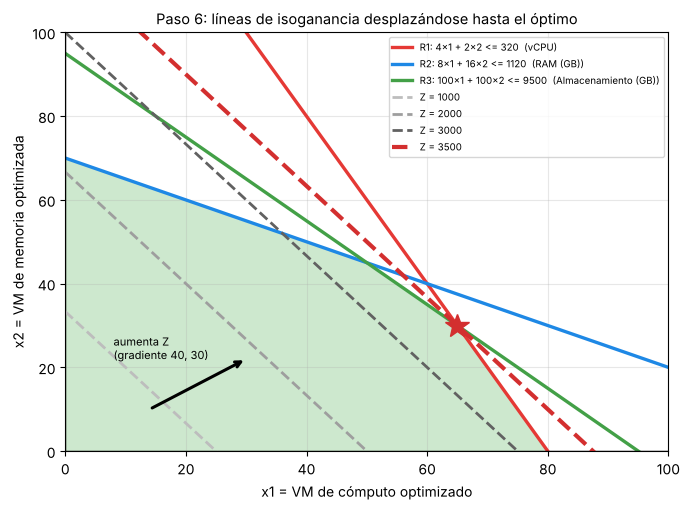

In [9]:
fig, ax = plt.subplots(figsize=(7, 5.2))
dibujar_restricciones(3, "Paso 6: líneas de isoganancia desplazándose hasta el óptimo", ax=ax)
for Z, col in zip([1000, 2000, 3000, mejor["Z"]], ["#bdbdbd", "#9e9e9e", "#616161", "#d32f2f"]):
    y = (Z - c[0] * xs) / c[1]
    ax.plot(xs, y, "--", color=col, lw=2 if Z != mejor["Z"] else 3, label=f"Z = {Z:.0f}")
ax.annotate("", xy=(30, 22), xytext=(14, 10), arrowprops=dict(arrowstyle="->", lw=2.2, color="black"))
ax.text(8, 22, "aumenta Z\n(gradiente 40, 30)", fontsize=8)
ax.plot(mejor["x1"], mejor["x2"], "*", color="#d32f2f", ms=18, zorder=5)
ax.legend(loc="upper right", fontsize=7)
plt.tight_layout()
plt.show()

---
# 8. Visualización de resultados

## 8.1 Solución con Python (SciPy `linprog`)

`linprog` **minimiza**, por lo que para maximizar $Z$ se minimiza $-Z$. Se resuelve con el método **HiGHS** y se compara con la solución gráfica.

Estado del solucionador: Optimization terminated successfully. (HiGHS Status 7: Optimal)
x1 (VM de cómputo optimizado) = 65.0000
x2 (VM de memoria optimizada) = 30.0000
Z máxima = 3500.00 USD por mes

¿Coincide con el método gráfico? -> True
¿La solución es entera (no requiere programación entera)? -> True


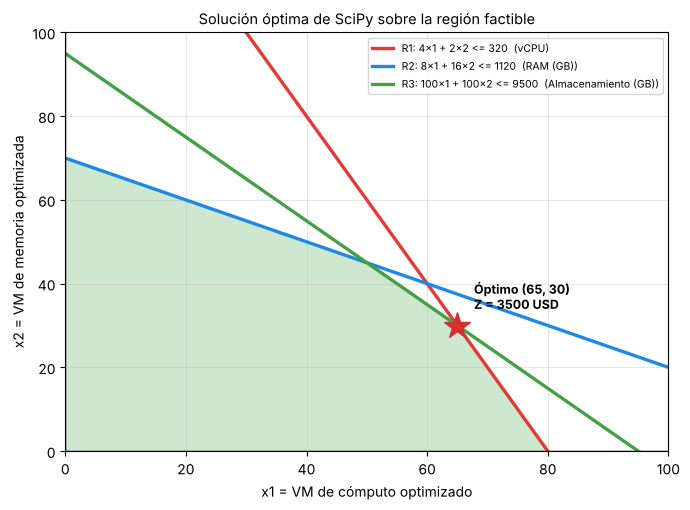

In [10]:
res = linprog(-c, A_ub=A, b_ub=b, bounds=[(0, None), (0, None)], method="highs")

print("Estado del solucionador:", res.message)
print(f"x1 (VM de cómputo optimizado) = {res.x[0]:.4f}")
print(f"x2 (VM de memoria optimizada) = {res.x[1]:.4f}")
print(f"Z máxima = {-res.fun:.2f} USD por mes")
print("\n¿Coincide con el método gráfico? ->", np.allclose(res.x, [mejor['x1'], mejor['x2']]) and np.isclose(-res.fun, mejor['Z']))
print("¿La solución es entera (no requiere programación entera)? ->", np.allclose(res.x, np.round(res.x)))

fig, ax = plt.subplots(figsize=(7, 5.2))
dibujar_restricciones(3, "Solución óptima de SciPy sobre la región factible", ax=ax)
ax.plot(*res.x, "*", color="#d32f2f", ms=20, zorder=5)
ax.annotate(f"Óptimo ({res.x[0]:.0f}, {res.x[1]:.0f})\nZ = {-res.fun:.0f} USD", res.x, textcoords="offset points",
            xytext=(12, 12), fontsize=9, fontweight="bold")
plt.tight_layout()
plt.show()

---
## 8.2 Uso de recursos, holguras y restricciones activas

Se sustituye el óptimo en cada restricción para calcular el **recurso utilizado**, la **holgura** (sobrante) y se identifica qué restricciones son **activas** (holgura = 0, cuello de botella).

            recurso  usado  disponible  holgura  % uso                       tipo
               vCPU  320.0         320      0.0 100.00 ACTIVA (cuello de botella)
           RAM (GB) 1000.0        1120    120.0  89.29                con holgura
Almacenamiento (GB) 9500.0        9500     -0.0 100.00 ACTIVA (cuello de botella)


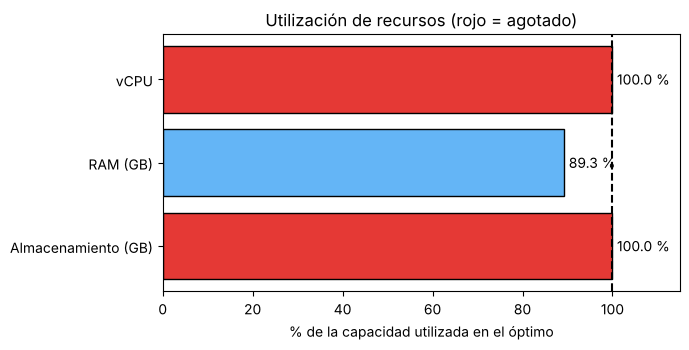

In [11]:
uso = A @ res.x
holgura = b - uso
df_uso = pd.DataFrame({
    "recurso": nombres_rest,
    "usado": uso,
    "disponible": b,
    "holgura": holgura,
    "% uso": 100 * uso / b,
    "tipo": ["ACTIVA (cuello de botella)" if abs(h) < 1e-7 else "con holgura" for h in holgura],
})
print(df_uso.round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 3.6))
barras = ax.barh(nombres_rest[::-1], (100 * uso / b)[::-1],
                 color=["#e53935" if abs(h) < 1e-7 else "#64b5f6" for h in holgura[::-1]], edgecolor="black")
for rect, v in zip(barras, (100 * uso / b)[::-1]):
    ax.text(v + 1, rect.get_y() + rect.get_height() / 2, f"{v:.1f} %", va="center")
ax.axvline(100, color="black", ls="--")
ax.set_xlim(0, 115)
ax.set_xlabel("% de la capacidad utilizada en el óptimo")
ax.set_title("Utilización de recursos (rojo = agotado)")
plt.tight_layout()
plt.show()

---
## 8.3 Precios sombra (análisis de sensibilidad)

El **precio sombra** de una restricción indica **cuánto aumentaría $Z$ por cada unidad adicional** del recurso (mientras no cambie el conjunto de restricciones activas). SciPy/HiGHS los entrega como `res.ineqlin.marginals` (con signo cambiado porque se minimizó $-Z$). Se espera que valgan **cero** para los recursos con holgura.

In [12]:
precios = -res.ineqlin.marginals
df_sombra = pd.DataFrame({"recurso": nombres_rest, "precio sombra (USD por unidad)": precios})
print(df_sombra.round(4).to_string(index=False))

# Comprobacion: aumentar 40 vCPU y volver a resolver
b2 = b.copy(); b2[0] += 40
res2 = linprog(-c, A_ub=A, b_ub=b2, bounds=[(0, None), (0, None)], method="highs")
print("\nComprobación: capacidad de vCPU de 320 a 360 (+40)")
print(f"   Nuevo óptimo: x1 = {res2.x[0]:.0f}, x2 = {res2.x[1]:.0f}, Z = {-res2.fun:.0f}")
print(f"   Incremento real de Z      : {-res2.fun - (-res.fun):.0f} USD")
print(f"   Predicho por precio sombra: {precios[0] * 40:.0f} USD  (= {precios[0]:.2f} x 40)")

            recurso  precio sombra (USD por unidad)
               vCPU                             5.0
           RAM (GB)                             0.0
Almacenamiento (GB)                             0.2

Comprobación: capacidad de vCPU de 320 a 360 (+40)
   Nuevo óptimo: x1 = 85, x2 = 10, Z = 3700
   Incremento real de Z      : 200 USD
   Predicho por precio sombra: 200 USD  (= 5.00 x 40)


---
## 8.4 ¿Hasta dónde vale la pena ampliar los vCPU?

Se resuelve el modelo repetidamente variando la capacidad de vCPU de 200 a 500 y se grafica la **ganancia máxima** resultante. La pendiente de la curva es el precio sombra y cambia cuando cambia el vértice óptimo.

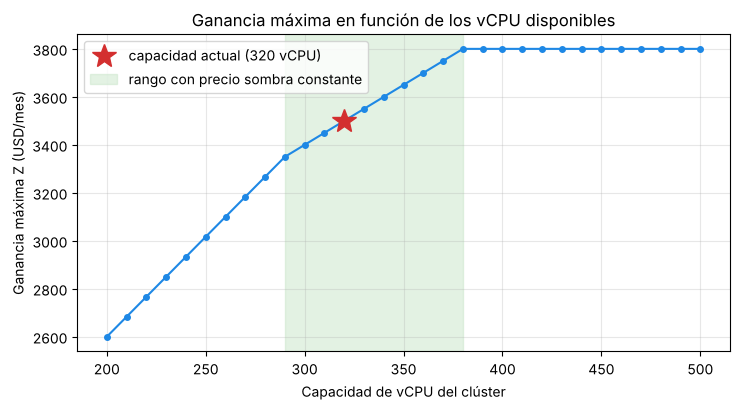

Pendiente (USD por vCPU adicional) por tramo:
   de 200 a 210 vCPU: 8.33
   de 230 a 240 vCPU: 8.33
   de 260 a 270 vCPU: 8.33
   de 290 a 300 vCPU: 5.00
   de 320 a 330 vCPU: 5.00
   de 350 a 360 vCPU: 5.00
   de 380 a 390 vCPU: -0.00
   de 410 a 420 vCPU: 0.00
   de 440 a 450 vCPU: 0.00
   de 470 a 480 vCPU: 0.00


In [13]:
caps = np.arange(200, 501, 10)
Zs = []
for cap in caps:
    bb = b.copy(); bb[0] = cap
    r = linprog(-c, A_ub=A, b_ub=bb, bounds=[(0, None), (0, None)], method="highs")
    Zs.append(-r.fun)
Zs = np.array(Zs)

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(caps, Zs, "o-", color="#1e88e5", ms=4)
ax.plot(320, -res.fun, "*", color="#d32f2f", ms=18, label="capacidad actual (320 vCPU)")
ax.axvspan(290, 380, color="#c8e6c9", alpha=0.5, label="rango con precio sombra constante")
ax.set_xlabel("Capacidad de vCPU del clúster")
ax.set_ylabel("Ganancia máxima Z (USD/mes)")
ax.set_title("Ganancia máxima en función de los vCPU disponibles")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

pend = np.diff(Zs) / np.diff(caps)
print("Pendiente (USD por vCPU adicional) por tramo:")
for a_, p_ in zip(caps[:-1][::3], pend[::3]):
    print(f"   de {a_:>3} a {a_ + 10:>3} vCPU: {p_:.2f}")


---
# 9. Interpretación de resultados y análisis final

**Solución óptima.**

$$x_1^*=65 \text{ VM de cómputo optimizado},\qquad x_2^*=30 \text{ VM de memoria optimizada},\qquad Z^*=\mathbf{3{,}500\ USD/mes}$$

| Vértice | $(x_1,x_2)$ | $Z$ (USD) |
|:-------:|:-----------:|:---------:|
| (0, 0) | (0, 0) | 0 |
| (80, 0) | 80 cómputo | 3,200 |
| **(65, 30)** | **65 y 30** | **3,500** |
| (50, 45) | 50 y 45 | 3,350 |
| (0, 70) | 70 memoria | 2,100 |

**Interpretación.**

- La mejor mezcla **no** consiste en ofrecer sólo la VM más rentable (80 VM de cómputo darían 3,200 USD): combinar ambos tipos aprovecha los recursos sobrantes y gana **300 USD más al mes**.
- En el óptimo se **agotan dos recursos**: los **vCPU** (4·65 + 2·30 = 320) y el **almacenamiento** (100·65 + 100·30 = 9,500 GB). La **RAM** se usa al 89.3 % (1,000 de 1,120 GB) y queda una **holgura de 120 GB**.
- Los **precios sombra** confirman el cuello de botella: **cada vCPU adicional vale 5 USD/mes** y **cada GB de almacenamiento adicional vale 0.20 USD/mes**, mientras que **la RAM vale 0** (sobra). Al subir la capacidad de 320 a 360 vCPU, la ganancia aumenta exactamente 200 USD (40 × 5), lo cual coincide con la predicción. Esta equivalencia es válida mientras la capacidad de vCPU esté entre **290 y 380**.
- La solución resultó **entera**, por lo que es directamente implementable (no se requiere programación entera).

**Aplicación al área de Tecnologías de la Información.**

- Ayuda a **dimensionar y priorizar inversiones**: ampliar vCPU o disco genera ingresos; comprar más RAM, en este momento, **no** aumenta la ganancia.
- Permite elegir la **mezcla de instancias** de un centro de datos o proveedor de nube y recalcularla cuando cambian precios o capacidades (basta modificar $c$, $A$ y $b$).
- Es la base de problemas mayores de **asignación de recursos**, *scheduling* de tareas y planeación de capacidad en servidores y contenedores.

---

# 10. Conclusiones individuales y del equipo

## Conclusión del equipo

La programación lineal permitió determinar la mezcla óptima de máquinas virtuales (65 de cómputo y 30 de memoria) que maximiza la ganancia a **3,500 USD mensuales**. La construcción gráfica paso a paso —restricción por restricción, vértices y líneas de isoganancia— mostró por qué el óptimo está en un vértice, y la solución con SciPy la confirmó. El análisis de holguras y de precios sombra aportó información de gestión: los vCPU y el almacenamiento son el cuello de botella, y la RAM tiene capacidad ociosa.

## Conclusión individual

**Integrante 1 – Fernando Dante Rodriguez Silva:** Con esta práctica entendí mucho mejor cómo funciona el método gráfico paso a paso y por qué la solución óptima siempre termina cayendo en una esquina de la región factible. Ver cómo cada restricción iba recortando el área sombreada y cómo las líneas de isoganancia avanzaban hasta tocar el punto $(65, 30)$ con $3,500\text{ USD}$ hizo que todo tuviera más sentido que solo hacer cuentas en papel. Lo que más me costó al principio fue revisar las 10 intersecciones entre rectas para distinguir cuáles vértices sí cumplían todas las restricciones y cuáles quedaban fuera. Este modelo lo aplicaría para planear la capacidad de servidores en la nube o repartir recursos de hardware cuando se tienen límites fijos de presupuesto y equipo.

**Integrante 2 – Jonathan Alberto López Fabián:** Lo más interesante de la actividad fue comprobar que combinar ambos tipos de máquinas virtuales ($65$ de cómputo y $30$ de memoria) da $300\text{ USD}$ más al mes que llenar el clúster únicamente con las VM más caras, y confirmar exactamente ese mismo resultado tanto gráficamente como con `linprog` en Python. La parte que más trabajo me costó fue recordar que `linprog` minimiza por defecto —por lo que hubo que cambiarle el signo a la función objetivo— y comprobar cómo se comporta la ganancia cuando se mueven los vCPU entre $290$ y $380$. Lo aplicaría en proyectos de infraestructura en la nube para decidir en qué componente conviene invertir más sin gastar dinero en recursos que se van a quedar sin usar.

**Integrante 3 – Brayan Michel Aguilar Torres:** En esta práctica aprendí a interpretar las holguras y los precios sombra para detectar cuellos de botella, como ver que los vCPU y el almacenamiento se agotaron al 100 % mientras que sobraron $120\text{ GB}$ de RAM. Mi principal dificultad fue entender al inicio qué significaba el precio sombra en la vida real y por qué la RAM valía $0$ aunque todavía quedara espacio disponible en el clúster. Este tipo de análisis lo usaría para optimizar costos en centros de datos, dimensionar instancias en servicios cloud o asignar tareas en servidores donde varios procesos compiten por CPU, memoria y disco.